In [2]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense, Input

In [ ]:
# Import data for training using u0 = cos(x/16).*(1+sin(x/16))
data_train = sio.loadmat("kuramoto_sivishinky_train.mat")
#Import data for testing
data_test = sio.loadmat("kuramoto_sivishinky_test.mat")

# Exporting the relevant data using u0 = cos(x/10).*(1+sin(x/10))
tt = data_train["tt"]
uu_train = data_train["uu"].T
uu_test= data_test["uu"].T


dict_keys(['__header__', '__version__', '__globals__', 'tt', 'uu', 'x'])


In [4]:
# Creating a function for splitting up data into training and test
def create_dataset(y, n_input):
    T = y.shape[1]
    X = np.array([y[:, i : i + n_input].T for i in range(T - n_input)])
    y = np.array([y[:, i + n_input] for i in range(T - n_input)])
    return X, y

In [5]:
Nt = tt.shape[1] # Number of timesteps taken
Nx = uu_train.shape[1] # Spatial resolution

# Create the input and output training data
t_train = tt
y_train = uu_train

X_train = uu_train[:-1]
y_train = uu_train[1:]


In [6]:
# Create the NN model
model = Sequential()
model.add(Input(shape=(Nx,)))
model.add(Dense(100))
model.add(Dense(Nx))
model.compile(loss="mean_squared_error", optimizer="adam")

2026-09-25 11:43:28.266382: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-09-25 11:43:28.266417: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-09-25 11:43:28.266424: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-09-25 11:43:28.266460: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-09-25 11:43:28.266471: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [7]:
# Train the model
model.fit(X_train, y_train, epochs=100, verbose = 0)

2026-09-25 11:43:28.704906: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


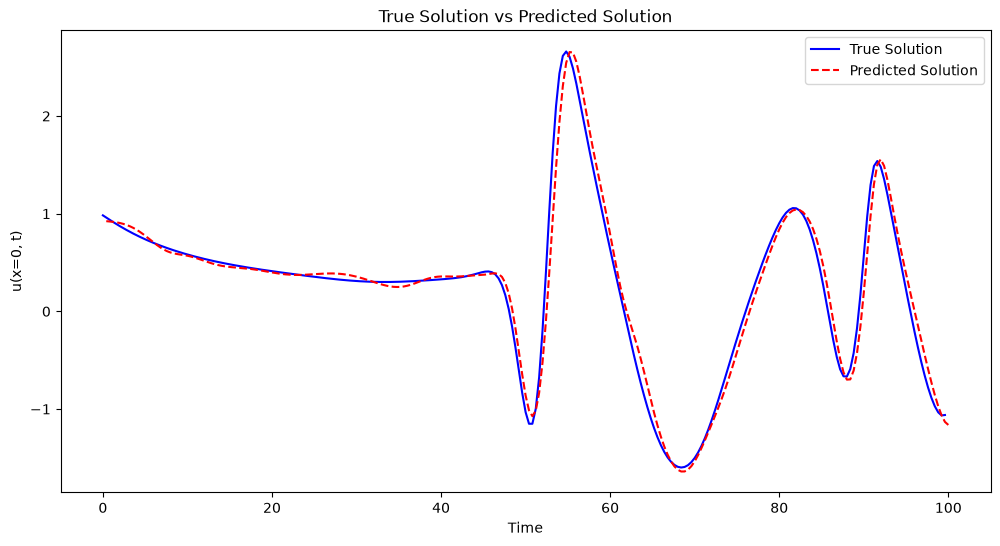

In [8]:
# Testing on the training dataset to see if the model can fit it
y_train_pred = model.predict(X_train, verbose = 0)

# Time axis matching y_test/y_test_pred (first n_input steps were consumed as input)
t_plot = tt.flatten()

# Plot true vs predicted at a single spatial location (e.g. x[0])
plt.figure(figsize=(12, 6))
plt.plot(t_plot[:-1], y_train[:, 0], label="True Solution", color="blue")
plt.plot(t_plot[1:], y_train_pred[:, 0], label="Predicted Solution", color="red", linestyle="--")

plt.xlabel("Time")
plt.ylabel("u(x=0, t)")
plt.title("True Solution vs Predicted Solution")
plt.legend()
plt.show()

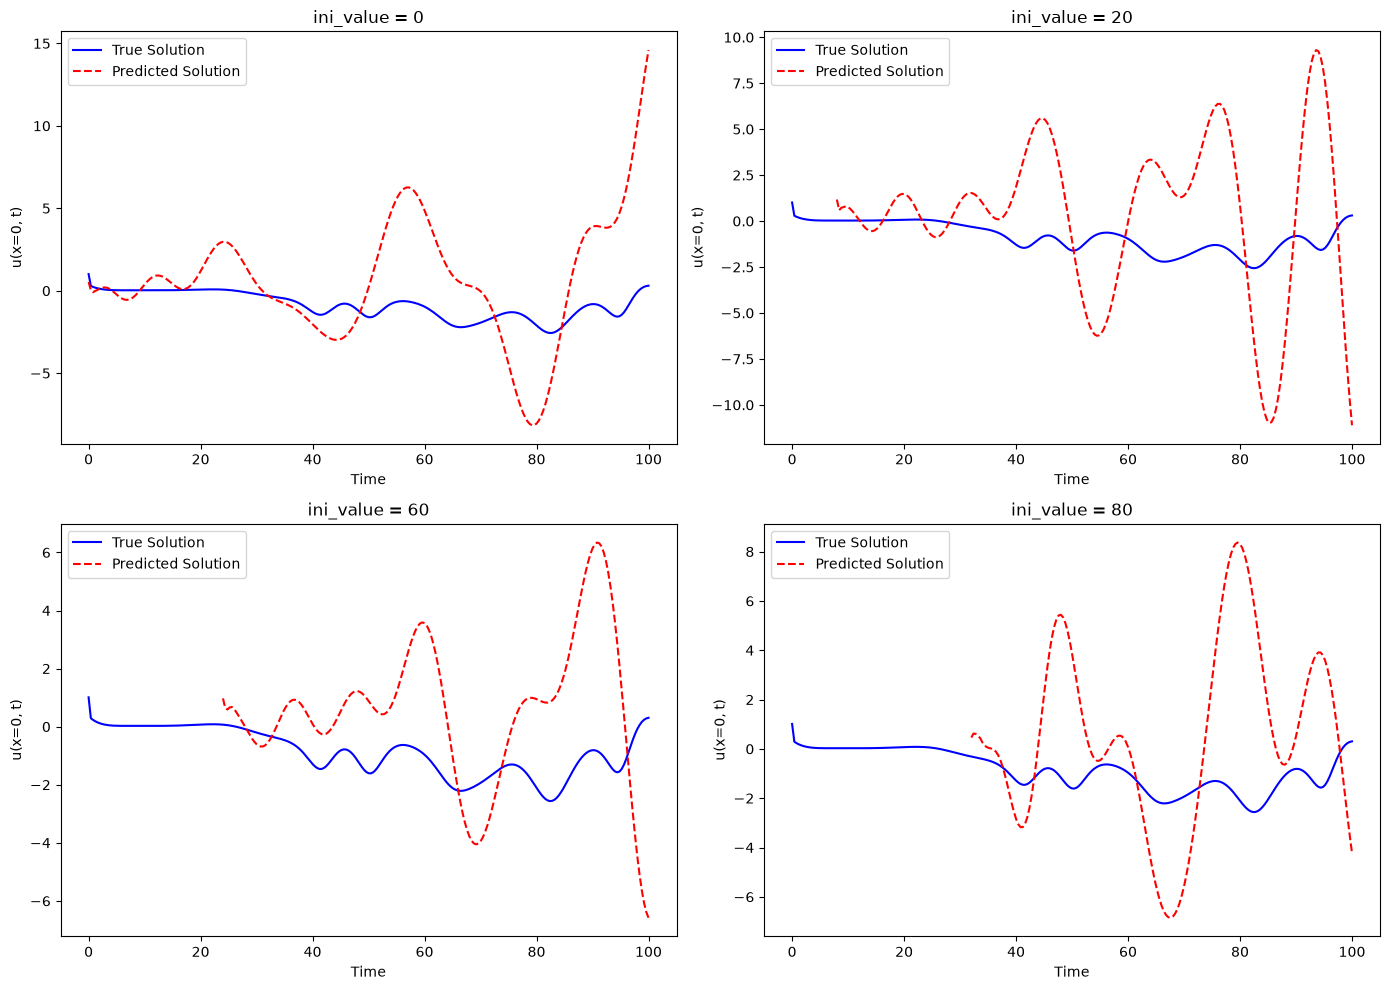

In [ ]:
# Make predictions and create subplots for each ini_value
ini_values = [0, 20, 60, 80]

# Copilot have assisted in creating the plotting structure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Create a 2x2 grid of subplots
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

# creating a forecasting machanism
for idx, i in enumerate(ini_values):
    u0 = uu_test[i]
    current = u0.reshape(1, Nx)
    forecast = []
    for k in range(i, len(uu_test)):
        prediction = model.predict(current, verbose=0)
        forecast.append(prediction[0])
        current = prediction
    forecast = np.array(forecast)
    
    # Plot true vs predicted for the current ini_value
    ax = axes[idx]
    ax.plot(t_plot, uu_test[:, 0], label="True Solution", color="blue")
    ax.plot(t_plot[i:], forecast[:, 0], label="Predicted Solution", color="red", linestyle="--")
    ax.set_xlabel("Time")
    ax.set_ylabel("u(x=0, t)")
    ax.set_title(f"ini_value = {i}")
    ax.legend()

# Adjust layout for better spacing
plt.tight_layout()
plt.show()

In [21]:
# Loading in the reaction_diffusion dataset
data_rd = sio.loadmat("reaction_diffusion_big.mat")

# Check what's inside
print(data_rd.keys())

dict_keys(['__header__', '__version__', '__globals__', 't', 'u', 'v', 'x', 'y'])


In [48]:
# Exporting relevant data
u = data_rd["u"]
t = data_rd["t"]
nx, ny, nt = u.shape

# Flattens the velocity for each timestep
u = u.reshape(nx * ny, nt)

# Generate SVD from data points
Uhat, Shat, VThat = np.linalg.svd(u, full_matrices=False)

In [42]:
# Finding ranks of system
# ...

# Using the first 3 ranks
r = [1, 2, 3]
train_time = int(nt*0.7)
train_list = []
test_list = []
model_list = []

for i in r:
    A = np.diag(Shat[:i]) @ VThat[:i, :]
    A = A.transpose()
    # Create the input and output training data
    train = A[:train_time]
    test = A[train_time:]
    train_list.append(train)
    test_list.append(test)

    X_train = train[:-1]
    y_train = train[1:]
    
    # Create the NN model
    model = Sequential()
    model.add(Input(shape=(i,)))
    model.add(Dense(100))
    model.add(Dense(i))
    model.compile(loss="mean_squared_error", optimizer="adam")
    
    
    # Train the model
    model.fit(X_train, y_train, epochs=100)
    
    model_list.append(model)



Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 79488.1953
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 64109.7617
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 50810.2305
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 39256.1602
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 29395.8770 
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 21232.5059
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 14832.7510 
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9685.0518 
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 6104.9126
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3602.4663
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1908.6351 
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 972.8818  
Epoch 13/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 434.6135
Epoch 14/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 199.1697 
Epoch 15/100
5/5 ━━━━━━━━━━━━━━━━━━━━

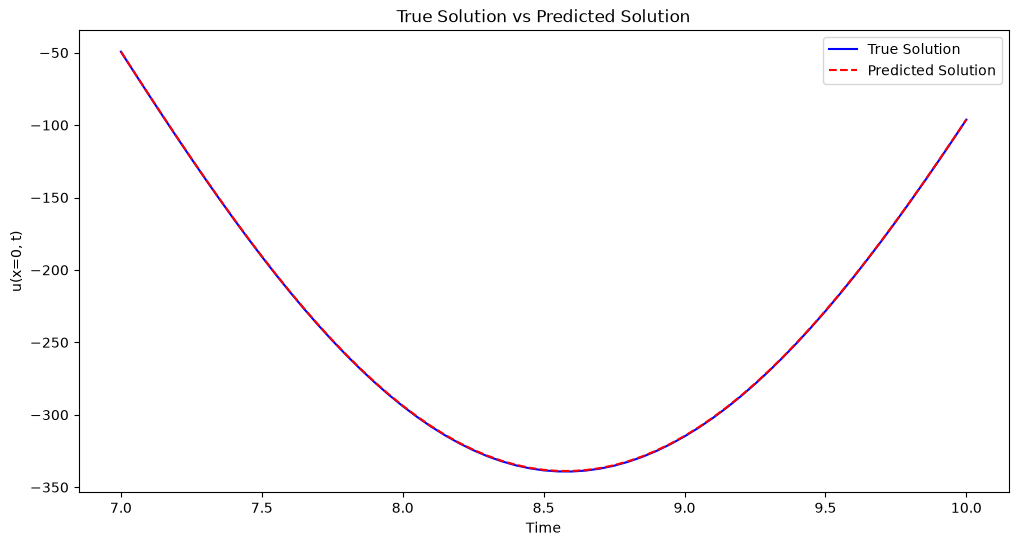

In [54]:
# Testing on the training dataset to see if the model can fit it
y_test_pred = model_list[0].predict(test_list[0], verbose = 0)

# Time axis matching y_test/y_test_pred (first n_input steps were consumed as input)

# Plot true vs predicted at a single spatial location (e.g. x[0])
plt.figure(figsize=(12, 6))
plt.plot(t.flatten()[train_time:], test_list[0][:, 0], label="True Solution", color="blue")
plt.plot(t.flatten()[train_time:], y_test_pred[:, 0], label="Predicted Solution", color="red", linestyle="--")

plt.xlabel("Time")
plt.ylabel("u(x=0, t)")
plt.title("True Solution vs Predicted Solution")
plt.legend()
plt.show()

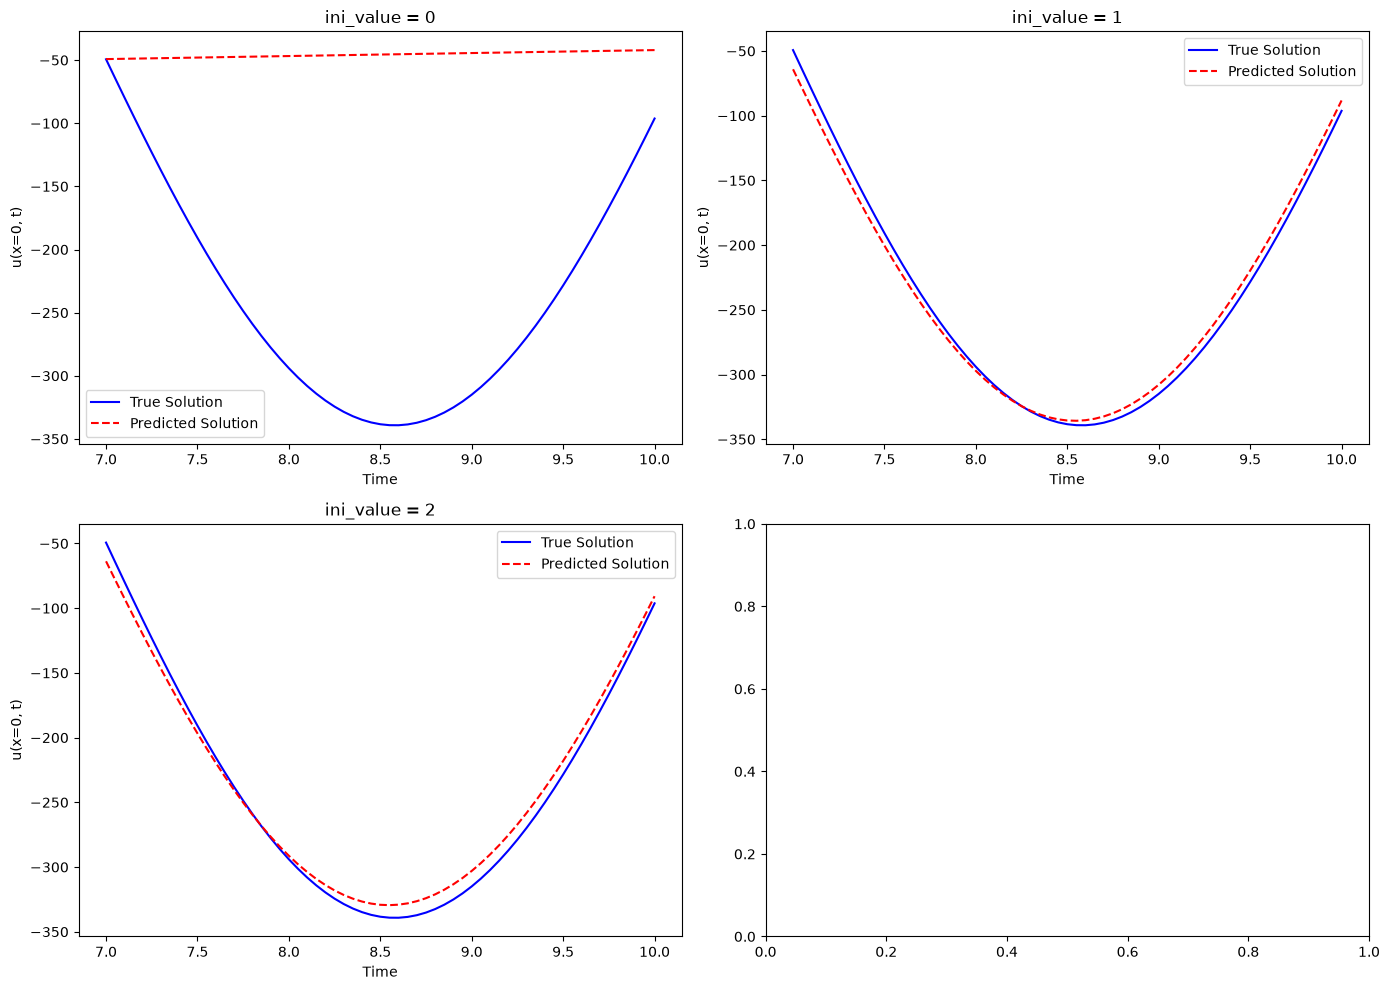

In [ ]:
# Copilot have assisted in creating the plotting structure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))  # Create a 2x2 grid of subplots
axes = axes.flatten()  # Flatten the 2D array of axes for easier indexing

# creating a forecasting machanism
for i in range(len(model_list)):
    u0 = test_list[i][0]
    current = u0.reshape(1, r[i])
    forecast = []
    for k in range(len(test_list[i])):
        prediction = model_list[i].predict(current, verbose=0)
        forecast.append(prediction[0])
        current = prediction
    forecast = np.array(forecast)
    

    # Plot true vs predicted for the current ini_value
    ax = axes[i]
    ax.plot(t.flatten()[train_time:], test_list[i][:, 0], label="True Solution", color="blue")
    ax.plot(t.flatten()[train_time:], forecast[:, 0], label="Predicted Solution", color="red", linestyle="--")
    ax.set_xlabel("Time")
    ax.set_ylabel("u(x=0, t)")
    ax.set_title(f"using rank = {i+1}")
    ax.legend()

# Adjust layout for better spacing
plt.tight_layout()
plt.show()